# CarbonCast — downloading and preparing data for a region

This notebook downloads everything CarbonCast needs for one region and writes it in the **same file formats as the bundled `data/<REGION>/` folder**, so the files can be used by `carbonIntensityCalculator.py`, `firstTierForecasts.py` and `secondTierForecasts.py` (and by the prediction notebook).

| What | Source | Account needed | Written to (`data_downloaded/<REGION>/…`) |
|---|---|---|---|
| Hourly electricity production by source — US | EIA Hourly Electric Grid Monitor (EIA-930) API | free API key | `<R>.csv`, `fuel_forecast/<R>_clean.csv` |
| Hourly electricity production by source — Europe | ENTSO-E Transparency Platform API | free security token | same |
| Hourly electricity production by source — Australia | Open Electricity API (successor of OpenNEM) | free API key | same |
| Day-ahead solar/wind forecasts (optional) | ENTSO-E (EU), CAISO OASIS (CISO) | as above / none | `fuel_forecast/<R>_<source>_clean.csv` |
| Carbon intensity (lifecycle + direct) | computed here from the production mix | – | `<R>_lifecycle_emissions.csv`, `<R>_direct_emissions.csv` |
| 96-h weather forecasts (5 variables) | NOAA GFS 0.25° — AWS open data (from 26 Feb 2021) or NCAR GDEX archive (from 2015) | none (AWS) / free account (GDEX) | `weather_data/<R>_AVG_*.csv`, `weather_data/<R>_aggregated_weather_data.csv`, `<R>_weather_forecast.csv` |

At the end, Section 7 explains how to feed these files to tier 1 / tier 2 (training new models is needed for periods other than 2020–2021, because the saved models were trained on that data).

## 0. Setup

Install the extra packages once (in the same environment you use for CarbonCast):

```bash
pip install requests entsoe-py openelectricity
# GRIB decoding for the weather data (needs the ecCodes library; conda is the easiest way on Windows):
conda install -c conda-forge cfgrib eccodes xarray
```

Get the credentials you need for your region and put them in environment variables (or paste them into the parameter cell — but don't commit them):

* **EIA** (US regions): register at https://www.eia.gov/opendata/ → `EIA_API_KEY`
* **ENTSO-E** (EU regions): create an account on https://transparency.entsoe.eu, then email transparency@entsoe.eu with subject "Restful API access" and the account email; afterwards generate a token under *My Account Settings → Web API Security Token* → `ENTSOE_API_KEY`
* **Open Electricity** (Australian regions): sign up at https://platform.openelectricity.org.au → `OPENELECTRICITY_API_KEY`
* **GFS weather**: nothing needed for the AWS route. For dates before 26 Feb 2021 use NCAR GDEX (free account, Section 5.3).

In [2]:
import os, re, io, json, math, time, zipfile, tempfile, warnings
from pathlib import Path
from datetime import datetime, timedelta
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

## 1. Parameters and region catalogue

Pick a region and a period. `END` is exclusive. Start small (a few weeks) to check everything works — a full year of 0.25° weather data is a large download (see Section 5).

The catalogue below contains every region the repo supports plus a few extra regions for which the repo lists weather bounding boxes. To add another region, add an entry with its data provider, the provider's code and a lat/lon bounding box.

In [ ]:
# ======================= PARAMETERS =======================
REGION = "CISO"
START  = "2024-01-01"        # UTC, inclusive
END    = "2024-02-01"        # UTC, exclusive

EIA_API_KEY             = os.environ.get("EIA_API_KEY", "")
ENTSOE_API_KEY          = os.environ.get("ENTSOE_API_KEY", "")
OPENELECTRICITY_API_KEY = os.environ.get("OPENELECTRICITY_API_KEY", "")

DOWNLOAD_DA_FORECASTS = True     # day-ahead solar/wind forecasts where available (ENTSO-E, CAISO)
GFS_SOURCE     = "aws"           # "aws" (>= 2021-02-26, no account) or "gdex_local" (files you downloaded from GDEX)
GFS_RESOLUTION = "0p25"          # "0p25" like the paper; "0p50"/"1p00" are 4x/16x smaller downloads
GFS_WORKERS    = 8               # parallel HTTP downloads
# ===========================================================

# Repo root = folder containing src/ and data/
NOTEBOOK_DIR = Path.cwd()
REPO = NOTEBOOK_DIR / "CarbonCast"
for cand in [REPO, *REPO.parents]:
    if (cand / "src").exists() and (cand / "data").exists():
        REPO = cand; break
OUT = REPO / "data_downloaded" / REGION
for sub in ("", "fuel_forecast", "weather_data", "weather_data/gfs_cache"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)
print("Repo:", REPO, "\nOutput folder:", OUT)

In [4]:
# provider, provider code, bbox (nlat, slat, wlon, elon) from src/weather/ds084.1_control.ctl, timezone
REGIONS = {
    # --- US (EIA-930 balancing authorities) ---
    "CISO":  dict(provider="eia", code="CISO", bbox=(42, 32, -124.75, -113.5),   tz="US/Pacific"),
    "PJM":   dict(provider="eia", code="PJM",  bbox=(43, 34.25, -91, -73.5),     tz="US/Eastern"),
    "ERCO":  dict(provider="eia", code="ERCO", bbox=(36.5, 25.25, -104.5, -93.25), tz="US/Central"),
    "ISNE":  dict(provider="eia", code="ISNE", bbox=(48, 40, -74.25, -66.5),     tz="US/Eastern"),
    "NYISO": dict(provider="eia", code="NYIS", bbox=(45.5, 40, -80.25, -71.25),  tz="US/Eastern"),
    "FPL":   dict(provider="eia", code="FPL",  bbox=(31.25, 24, -83.5, -79.5),   tz="US/Eastern"),
    "BPAT":  dict(provider="eia", code="BPAT", bbox=(49.5, 39.5, -125.25, -105.5), tz="US/Pacific"),
    "MISO":  dict(provider="eia", code="MISO", bbox=(50, 28.5, -107.75, -81.75), tz="US/Eastern"),
    "SWPP":  dict(provider="eia", code="SWPP", bbox=(49.5, 30.25, -107.75, -89.5), tz="US/Central"),
    "SOCO":  dict(provider="eia", code="SOCO", bbox=(35.5, 29.25, -90.5, -80.25), tz="US/Central"),
    # --- Europe (ENTSO-E areas) ---
    "DE":    dict(provider="entsoe", code="DE",   bbox=(55.25, 47.25, 5.75, 15),  tz="CET"),
    "NL":    dict(provider="entsoe", code="NL",   bbox=(53.5, 50.75, 3.25, 7),    tz="CET"),
    "ES":    dict(provider="entsoe", code="ES",   bbox=(43.75, 36, -9.25, 3.5),   tz="CET"),
    "SE":    dict(provider="entsoe", code="SE",   bbox=(69, 55.25, 11.25, 21.25), tz="CET"),
    "PL":    dict(provider="entsoe", code="PL",   bbox=(54.75, 49, 14, 24),       tz="CET"),
    "FR":    dict(provider="entsoe", code="FR",   bbox=(51.25, 42.25, -5.25, 8.25), tz="CET"),
    "BE":    dict(provider="entsoe", code="BE",   bbox=(51.5, 49.5, 2.5, 6.25),   tz="CET"),
    "FI":    dict(provider="entsoe", code="FI",   bbox=(70, 59.75, 20.5, 31.5),   tz="EET"),
    "DK-DK2":dict(provider="entsoe", code="DK_2", bbox=(57.75, 54.75, 7.25, 11.25), tz="CET"),
    # --- Australia (NEM regions via Open Electricity) ---
    "AUS_QLD": dict(provider="openelectricity", code="QLD1", bbox=(-8.75, -29.75, 137.5, 154), tz="Australia/Brisbane"),
    "AUS_NSW": dict(provider="openelectricity", code="NSW1", bbox=(-34.75, -36.5, 148.25, 150), tz="Australia/Sydney"),
    "AUS_SA":  dict(provider="openelectricity", code="SA1",  bbox=(-25.5, -38.5, 128.5, 141.5), tz="Australia/Adelaide"),
}
R = REGIONS[REGION]
START_TS, END_TS = pd.Timestamp(START), pd.Timestamp(END)
HOURS = pd.date_range(START_TS, END_TS, freq="h", inclusive="left", name="UTC time")

# Source names and column order used by the repo for this region (if it is one of the 13 originals)
def load_json5(path):
    text = Path(path).read_text(encoding="utf-8")
    text = re.sub(r'("(?:\\.|[^"\\])*")|//[^\n]*', lambda m: m.group(1) or "", text)
    return json.loads(re.sub(r",\s*([}\]])", r"\1", text))
first_cfg = load_json5(REPO / "src" / "firstTierConfig.json")
REPO_SOURCES = [s.lower() for s in first_cfg.get(REGION, {}).get("SOURCES", [])]
print(REGION, R, "\nRepo source order:", REPO_SOURCES or "(new region - order taken from the data)")

CISO {'provider': 'eia', 'code': 'CISO', 'bbox': (42, 32, -124.75, -113.5), 'tz': 'US/Pacific'} 
Repo source order: ['coal', 'nat_gas', 'nuclear', 'oil', 'hydro', 'solar', 'wind', 'other']


## 2. Hourly electricity production by source

Each provider reports its own fuel categories. They are mapped to CarbonCast's source names (`coal, nat_gas, oil, nuclear, hydro, solar, wind, biomass, geothermal, other, unknown`), summed per hour, converted to **UTC**, and resampled to hourly means (some European areas report every 15 min). Negative values (storage charging, pumping) are clipped to 0 as in `carbonIntensityCalculator.py`, and storage is left out so it doesn't count as generation.

Edit the mapping dictionaries if you want to treat a category differently.

### 2.1 US — EIA-930 (`api.eia.gov/v2/electricity/rto/fuel-type-data`)
EIA reports hourly values in MWh with UTC timestamps (`period`, format `YYYY-MM-DDTHH`). The API returns at most 5 000 rows per call, so the function pages through results month by month.

In [5]:
EIA_FUEL_MAP = {"COL": "coal", "NG": "nat_gas", "NUC": "nuclear", "OIL": "oil", "WAT": "hydro",
                "SUN": "solar", "WND": "wind", "GEO": "geothermal", "OTH": "other", "UNK": "unknown",
                # storage: not generation -> dropped
                "BAT": None, "PS": None, "SNB": None, "OES": None}

def month_chunks(start, end):
    edges = list(pd.date_range(start.normalize().replace(day=1), end, freq="MS"))
    edges = [start] + [e for e in edges if start < e < end] + [end]
    return list(zip(edges[:-1], edges[1:]))

def fetch_eia_generation(respondent, start, end, api_key):
    assert api_key, "Set EIA_API_KEY (https://www.eia.gov/opendata/)"
    url = "https://api.eia.gov/v2/electricity/rto/fuel-type-data/data/"
    rows = []
    for s, e in month_chunks(start, end):
        offset = 0
        while True:
            params = {"api_key": api_key, "frequency": "hourly", "data[0]": "value",
                      "facets[respondent][]": respondent,
                      "start": s.strftime("%Y-%m-%dT%H"), "end": (e - pd.Timedelta(hours=1)).strftime("%Y-%m-%dT%H"),
                      "sort[0][column]": "period", "sort[0][direction]": "asc",
                      "offset": offset, "length": 5000}
            r = requests.get(url, params=params, timeout=120)
            r.raise_for_status()
            resp = r.json()["response"]
            data = resp.get("data", [])
            rows += data
            offset += len(data)
            if not data or offset >= int(resp.get("total", 0)):
                break
        print(f"  EIA {respondent} {s.date()} - {e.date()}: {offset} rows")
    df = pd.DataFrame(rows)
    df["period"] = pd.to_datetime(df["period"], format="%Y-%m-%dT%H")
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    unknown = sorted(set(df["fueltype"]) - set(EIA_FUEL_MAP))
    if unknown:
        print("  Unmapped EIA fuel types (counted as 'other'):", unknown)
    df["source"] = df["fueltype"].map(lambda f: EIA_FUEL_MAP.get(f, "other"))
    df = df[df["source"].notna()]
    return df.pivot_table(index="period", columns="source", values="value", aggfunc="sum")

### 2.2 Europe — ENTSO-E (`entsoe-py`)
`query_generation` returns *Actual Generation per Production Type* (document A75). Where an area also reports consumption (e.g. pumped storage), the columns are a MultiIndex and only *Actual Aggregated* is kept.

In [6]:
ENTSOE_MAP = {
    "Biomass": "biomass", "Waste": "biomass",
    "Fossil Brown coal/Lignite": "coal", "Fossil Hard coal": "coal", "Fossil Coal-derived gas": "coal",
    "Fossil Peat": "coal", "Fossil Oil shale": "coal",
    "Fossil Gas": "nat_gas", "Fossil Oil": "oil", "Nuclear": "nuclear", "Geothermal": "geothermal",
    "Hydro Run-of-river and poundage": "hydro", "Hydro Water Reservoir": "hydro", "Hydro Pumped Storage": "hydro",
    "Solar": "solar", "Wind Onshore": "wind", "Wind Offshore": "wind",
    "Other": "unknown", "Other renewable": "unknown", "Marine": "unknown",
    "Energy storage": None,
}

def _entsoe_client(api_key):
    assert api_key, "Set ENTSOE_API_KEY (see Section 0)"
    from entsoe import EntsoePandasClient
    return EntsoePandasClient(api_key=api_key)

def _to_hourly_utc(df):
    df.index = pd.DatetimeIndex(df.index).tz_convert("UTC").tz_localize(None)
    return df.resample("h").mean()

def fetch_entsoe_generation(area, start, end, api_key):
    from entsoe.exceptions import NoMatchingDataError
    client, parts = _entsoe_client(api_key), []
    for s, e in month_chunks(start, end):
        try:
            g = client.query_generation(area, start=pd.Timestamp(s, tz="UTC"), end=pd.Timestamp(e, tz="UTC"))
        except NoMatchingDataError:
            print(f"  ENTSO-E {area} {s.date()}: no data"); continue
        if isinstance(g, pd.Series):
            g = g.to_frame()
        if isinstance(g.columns, pd.MultiIndex):
            keep = [c for c in g.columns if c[1] == "Actual Aggregated"]
            g = g[keep]; g.columns = [c[0] for c in keep]
        parts.append(_to_hourly_utc(g))
        print(f"  ENTSO-E {area} {s.date()} - {e.date()}: {len(g)} rows, types: {list(g.columns)}")
    raw = pd.concat(parts).sort_index()
    raw = raw[~raw.index.duplicated()]
    unknown = sorted(set(raw.columns) - set(ENTSOE_MAP))
    if unknown:
        print("  Unmapped ENTSO-E types (counted as 'unknown'):", unknown)
    names = [ENTSOE_MAP.get(c, "unknown") for c in raw.columns]
    keep = [n is not None for n in names]
    return raw.loc[:, keep].T.groupby([n for n in names if n is not None]).sum(min_count=1).T

### 2.3 Australia — Open Electricity (`openelectricity` SDK)
Hourly power by fuel technology for one NEM region. Timestamps come back in NEM time (AEST, UTC+10, no daylight saving) and are converted to UTC. Requests are chunked by month. Note: how far back you can query depends on your Open Electricity plan; for older data the AEMO NEMWEB archive is the primary source.

In [7]:
def map_fueltech(ft):
    ft = str(ft).lower()
    if ft.startswith("coal"): return "coal"
    if ft.startswith("gas"): return "nat_gas"
    if ft in ("distillate",) or ft.startswith("oil"): return "oil"
    if ft.startswith("hydro"): return "hydro"
    if ft.startswith("wind"): return "wind"
    if ft.startswith("solar"): return "solar"
    if ft.startswith("bioenergy") or ft.startswith("biomass"): return "biomass"
    if ft.startswith("nuclear"): return "nuclear"
    return None   # battery, pumps, imports/exports, ...

def fetch_openelectricity_generation(region_code, start, end, api_key):
    assert api_key, "Set OPENELECTRICITY_API_KEY (https://platform.openelectricity.org.au)"
    os.environ["OPENELECTRICITY_API_KEY"] = api_key
    from openelectricity import OEClient
    from openelectricity.types import DataMetric
    NEM_OFFSET = pd.Timedelta(hours=10)
    parts = []
    with OEClient() as client:
        for s, e in month_chunks(start, end):
            resp = client.get_network_data(network_code="NEM", metrics=[DataMetric.POWER], interval="1h",
                                           date_start=(s + NEM_OFFSET).to_pydatetime(),
                                           date_end=(e + NEM_OFFSET).to_pydatetime(),
                                           primary_grouping="network_region", secondary_grouping="fueltech")
            df = resp.to_pandas()
            reg_col = next((c for c in ("network_region", "region") if c in df.columns), None)
            val_col = next((c for c in ("power", "value") if c in df.columns), None)
            assert reg_col and val_col and "fueltech" in df.columns, f"Unexpected columns: {list(df.columns)}"
            df = df[df[reg_col].astype(str).str.upper() == region_code]
            parts.append(df[["interval", "fueltech", val_col]].rename(columns={val_col: "value"}))
            print(f"  Open Electricity {region_code} {s.date()} - {e.date()}: {len(df)} rows")
    df = pd.concat(parts)
    df["interval"] = pd.to_datetime(df["interval"])
    if df["interval"].dt.tz is not None:
        df["interval"] = df["interval"].dt.tz_convert("UTC").dt.tz_localize(None)
    else:
        df["interval"] = df["interval"] - NEM_OFFSET          # naive NEM time -> UTC
    df["source"] = df["fueltech"].map(map_fueltech)
    print("  Fuel techs left out:", sorted(df.loc[df["source"].isna(), "fueltech"].unique()))
    df = df[df["source"].notna()]
    return df.pivot_table(index="interval", columns="source", values="value", aggfunc="sum")

### 2.4 Download, clean and save

Cleaning matches what the repo's files look like: one row per UTC hour with no gaps, negatives set to 0, short gaps (≤ 3 h) interpolated and longer gaps forward-filled. Columns follow the repo's source order for the original regions; sources the repo doesn't list for that region are reported (and kept at the end).

In [8]:
fetchers = {"eia": lambda: fetch_eia_generation(R["code"], START_TS, END_TS, EIA_API_KEY),
            "entsoe": lambda: fetch_entsoe_generation(R["code"], START_TS, END_TS, ENTSOE_API_KEY),
            "openelectricity": lambda: fetch_openelectricity_generation(R["code"], START_TS, END_TS, OPENELECTRICITY_API_KEY)}
gen_raw = fetchers[R["provider"]]()
gen_raw.to_csv(OUT / f"{REGION}_generation_raw.csv")

  EIA CISO 2024-01-01 - 2024-02-01: 5952 rows


744 hours, 0 hours had no data at all and were filled


source,coal,nat_gas,nuclear,oil,hydro,solar,wind,other
UTC time,,,,,,,,
2024-01-01 00:00:00,0,10409,2232,46,1746,4340,98,0
2024-01-01 01:00:00,0,11235,2233,46,2014,2146,133,672
2024-01-01 02:00:00,0,12189,2232,46,2925,461,185,1147
2024-01-01 03:00:00,0,12660,2237,46,3433,0,254,2515
2024-01-01 04:00:00,0,12493,2239,46,3431,0,291,1793


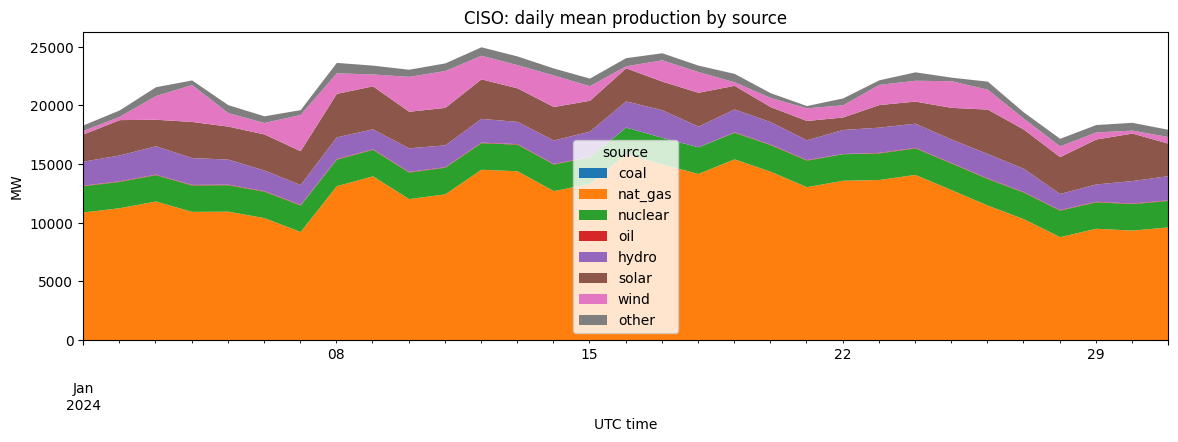

In [9]:
def clean_generation(raw, hours, source_order):
    df = raw.copy()
    df.index = pd.DatetimeIndex(df.index)
    df = df[~df.index.duplicated()].reindex(hours)
    n_missing = int(df.isna().all(axis=1).sum())
    df = df.clip(lower=0).interpolate(limit=3, limit_area="inside").ffill().bfill().fillna(0)
    df = df.loc[:, (df != 0).any()] if not source_order else df       # drop all-zero columns for new regions
    if source_order:
        extra = [c for c in df.columns if c not in source_order]
        missing = [c for c in source_order if c not in df.columns]
        if extra:   print("Sources not in the repo's list for this region (kept at the end):", extra)
        if missing: print("Repo sources with no data in this period (filled with 0):", missing)
        for c in missing: df[c] = 0.0
        df = df[source_order + extra]
    print(f"{len(df)} hours, {n_missing} hours had no data at all and were filled")
    return df.round(2)

gen = clean_generation(gen_raw, HOURS, REPO_SOURCES)
SOURCES = list(gen.columns)

def write_repo_csv(df, path, time_fmt="%Y-%m-%dT%H:%M"):
    out = df.copy(); out.index = out.index.strftime(time_fmt); out.index.name = "UTC time"
    out.to_csv(path)

write_repo_csv(gen, OUT / f"{REGION}.csv", "%Y-%m-%d %H:%M:%S")           # input of carbonIntensityCalculator.py -r
write_repo_csv(gen, OUT / "fuel_forecast" / f"{REGION}_clean.csv")         # input of firstTierForecasts.py
display(gen.head())

ax = gen.resample("D").mean().plot.area(figsize=(14, 4), linewidth=0)
ax.set_ylabel("MW"); ax.set_title(f"{REGION}: daily mean production by source"); plt.show()

## 3. Carbon intensity (lifecycle and direct)

Same formula and emission factors as `src/carbonIntensityCalculator.py`: $CI = \sum_i E_i\,CEF_i / \sum_i E_i$. The output has the same layout as the bundled `<R>_<lifecycle|direct>_emissions.csv` files (row number, `UTC time`, `carbon_intensity`, then the sources).

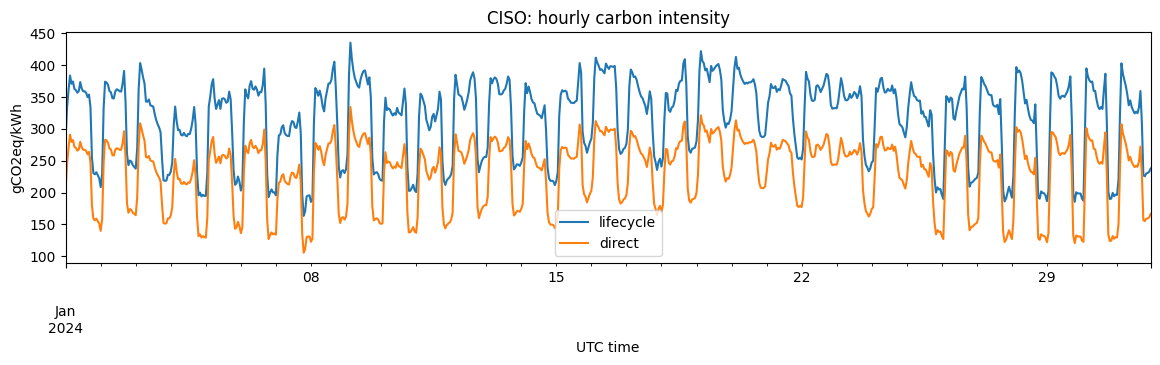

In [10]:
CEF_LIFECYCLE = {"coal": 820, "biomass": 230, "nat_gas": 490, "geothermal": 38, "hydro": 24, "nuclear": 12,
                 "oil": 650, "solar": 45, "unknown": 700, "other": 700, "wind": 11}
CEF_DIRECT    = {"coal": 760, "biomass": 0, "nat_gas": 370, "geothermal": 0, "hydro": 0, "nuclear": 0,
                 "oil": 406, "solar": 0, "unknown": 575, "other": 575, "wind": 0}
if REGION == "SE":                                   # special case in carbonIntensityCalculator.py
    CEF_LIFECYCLE.update(unknown=292.9, other=292.9)

def carbon_intensity(gen, cef):
    total = gen.sum(axis=1).replace(0, np.nan)
    ci = (gen * pd.Series(cef)[gen.columns]).sum(axis=1) / total
    return ci.ffill().round(2)            # all-zero hours: previous hour's value (as in the repo)

for kind, cef in (("lifecycle", CEF_LIFECYCLE), ("direct", CEF_DIRECT)):
    em = gen.copy()
    em.insert(0, "carbon_intensity", carbon_intensity(gen, cef))
    em = em.reset_index()
    em["UTC time"] = em["UTC time"].dt.strftime("%Y-%m-%d %H:%M:%S")
    em.to_csv(OUT / f"{REGION}_{kind}_emissions.csv")          # leading unnamed index column, like the repo
    em.set_index(pd.to_datetime(em["UTC time"]))["carbon_intensity"].plot(figsize=(14, 3), label=kind)
plt.ylabel("gCO2eq/kWh"); plt.legend(); plt.title(f"{REGION}: hourly carbon intensity"); plt.show()

## 5. 96-hour weather forecasts (GFS)

CarbonCast uses five forecast variables from the **00 UTC run of NOAA's GFS 0.25°** model, each averaged over the region's bounding box with grid-cell-area weights (as in `src/weather/dataCollectionScript.py`):

| column | GFS field | lead times used |
|---|---|---|
| `forecast_avg_wind_speed_wMean` | √(UGRD² + VGRD²) at 10 m (m/s) | 3, 6, …, 96 h |
| `forecast_avg_temperature_wMean` | TMP at 2 m (K) | 3, 6, …, 96 h |
| `forecast_avg_dewpoint_wMean` | DPT at 2 m (K) | 3, 6, …, 96 h |
| `forecast_avg_dswrf_wMean` | DSWRF at surface, 3/6-h averages (W/m²) | 0-3, 0-6, 6-9, 6-12, … |
| `forecast_avg_precipitation_wMean` | APCP at surface, 3/6-h accumulations (kg/m²) | 0-3, 0-6, 6-9, 6-12, … |

The pipeline has three stages, mirroring the repo's scripts:

1. **Per-run tables** `weather_data/<R>_AVG_<VAR>.csv` — one row per daily run, one column per lead time (same format as the repo's `dataCollectionScript.py` output).
2. **Hourly blocks** `weather_data/<R>_aggregated_weather_data.csv` — 96 hourly rows per run (same logic as `cleanWeatherData.py`: each hour takes the next 3-hourly value; hour 0 takes the previous run's 24-h value).
3. **Model input** `<R>_weather_forecast.csv` — the aggregated file with each block **re-labelled one day earlier** (block labelled day *d* holds the run of day *d+1*, i.e. forecasts valid from *d+1* 00 UTC). I checked this against the bundled files: `PL_weather_forecast.csv` equals `PL_aggregated_weather_data.csv` shifted by 96 rows, and the weather columns of `*_96hr_forecasts.csv` equal `*_weather_forecast.csv`. Combined with how tier 2 pairs inputs (Section 4.2 of the prediction notebook), this means the weather used for predicting day *d+1* is the forecast valid for day *d+1*.

### 5.1 Area-weighted regional mean (from the repo)

In [11]:
def earth_radius(lat):
    # WGS84 radius at geodetic latitude (dataCollectionScript.earth_radius)
    a, b = 6378137, 6356752.3142
    e2 = 1 - (b**2 / a**2)
    lat_gc = np.arctan((1 - e2) * np.tan(np.deg2rad(lat)))
    return (a * (1 - e2) ** 0.5) / (1 - (e2 * np.cos(lat_gc) ** 2)) ** 0.5

def area_grid(lat, lon):
    # grid-cell areas in m^2, shape (lat, lon)  (dataCollectionScript.area_grid)
    xlon, ylat = np.meshgrid(lon, lat)
    R_ = earth_radius(ylat)
    dy = np.deg2rad(np.gradient(ylat, axis=0)) * R_
    dx = np.deg2rad(np.gradient(xlon, axis=1)) * R_ * np.cos(np.deg2rad(ylat))
    return dy * dx

def crop_bbox(values, lat, lon, bbox):
    # values (lat, lon) on a global grid -> sub-grid inside bbox; handles 0..360 longitudes and the 0° seam
    nlat, slat, wlon, elon = bbox
    lon180 = ((np.asarray(lon) + 180) % 360) - 180
    order = np.argsort(lon180)
    lon180, values = lon180[order], np.asarray(values)[:, order]
    li = (lat >= slat) & (lat <= nlat)
    lj = (lon180 >= wlon) & (lon180 <= elon)
    return values[np.ix_(li, lj)], np.asarray(lat)[li], lon180[lj]

def regional_mean(values, lat, lon, bbox):
    sub, la, lo = crop_bbox(values, lat, lon, bbox)
    w = np.abs(area_grid(la, lo))
    return float(np.nansum(sub * w) / np.sum(w[~np.isnan(sub)]))

### 5.2 AWS open data (runs from 26 Feb 2021 onwards, no account)

GFS files on `noaa-gfs-bdp-pds` are ~500 MB each, but every file has an `.idx` inventory with the byte range of each field, so only the 6 needed fields are downloaded (≈ 0.5–1 MB each at 0.25°, i.e. ~150 MB per day; ~10 MB per day at 1°). Results are cached per run in `weather_data/gfs_cache/`, so the cell can be re-run to resume.

In [12]:
LEADS = list(range(3, 97, 3))
VARS = ["wind", "temp", "dpt", "dswrf", "pcp"]

def interval_start(lead):          # 0-3, 0-6, 6-9, 6-12, ... (GFS 3/6-h buckets)
    return lead - 3 if (lead // 3) % 2 == 1 else lead - 6

def gfs_wanted(lead):
    a = interval_start(lead)
    return {"u":     ("UGRD", "10 m above ground", f"{lead} hour fcst"),
            "v":     ("VGRD", "10 m above ground", f"{lead} hour fcst"),
            "temp":  ("TMP",  "2 m above ground",  f"{lead} hour fcst"),
            "dpt":   ("DPT",  "2 m above ground",  f"{lead} hour fcst"),
            "dswrf": ("DSWRF", "surface", (a, lead, "ave")),
            "pcp":   ("APCP",  "surface", (a, lead, "acc"))}

def _interval(desc):               # "6-9 hour ave fcst" -> (6, 9, "ave"); handles 'day' units
    m = re.match(r"(\d+)-(\d+) (hour|day) (ave|acc) fcst", desc)
    if not m: return None
    k = 24 if m.group(3) == "day" else 1
    return int(m.group(1)) * k, int(m.group(2)) * k, m.group(4)

def parse_idx(text):
    lines = [l.split(":") for l in text.strip().splitlines()]
    out = []
    for i, p in enumerate(lines):
        start = int(p[1]); end = int(lines[i + 1][1]) - 1 if i + 1 < len(lines) else None
        out.append(dict(var=p[3], level=p[4], fcst=p[5], start=start, end=end))
    return out

def find_message(idx, want):
    var, level, fc = want
    for m in idx:
        if m["var"] != var or m["level"] != level: continue
        if isinstance(fc, str) and m["fcst"] == fc: return m
        if isinstance(fc, tuple) and _interval(m["fcst"]) == fc: return m
    raise KeyError(f"{var}:{level}:{fc} not in inventory")

session = requests.Session()
def gfs_url(run, lead, res):
    base = "https://noaa-gfs-bdp-pds.s3.amazonaws.com"
    for path in (f"gfs.{run:%Y%m%d}/00/atmos", f"gfs.{run:%Y%m%d}/00"):
        url = f"{base}/{path}/gfs.t00z.pgrb2.{res}.f{lead:03d}"
        r = session.get(url + ".idx", timeout=60)
        if r.ok: return url, r.text
    raise FileNotFoundError(f"GFS {run:%Y-%m-%d} f{lead:03d} not on AWS")

def download_message(url, m, path):
    hdr = {"Range": f"bytes={m['start']}-{'' if m['end'] is None else m['end']}"}
    for attempt in range(4):
        try:
            r = session.get(url, headers=hdr, timeout=120); r.raise_for_status()
            Path(path).write_bytes(r.content); return path
        except Exception:
            time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"failed: {url} {hdr}")

In [13]:
def read_grib_field(path):
    import xarray as xr
    ds = xr.open_dataset(path, engine="cfgrib", backend_kwargs={"indexpath": ""})
    da = ds[list(ds.data_vars)[0]].load()
    vals, lat, lon = np.squeeze(da.values), da.latitude.values, da.longitude.values
    ds.close()
    return vals, lat, lon

def process_run_aws(run, bbox, res=GFS_RESOLUTION, workdir=None):
    # -> {var: {lead: regional mean}} for one 00 UTC run
    workdir = Path(workdir or tempfile.mkdtemp())
    jobs = []
    for lead in LEADS:
        url, idx_text = gfs_url(run, lead, res)
        idx = parse_idx(idx_text)
        for key, want in gfs_wanted(lead).items():
            jobs.append((lead, key, url, find_message(idx, want), workdir / f"{run:%Y%m%d}_{lead:03d}_{key}.grib2"))
    with ThreadPoolExecutor(GFS_WORKERS) as ex:
        list(ex.map(lambda j: download_message(j[2], j[3], j[4]), jobs))
    paths = {(lead, key): p for lead, key, _, _, p in jobs}
    out = {v: {} for v in VARS}
    for lead in LEADS:                     # decode one lead at a time (global 0.25° fields are large)
        u, lat, lon = read_grib_field(paths[(lead, "u")]); v, _, _ = read_grib_field(paths[(lead, "v")])
        out["wind"][lead] = regional_mean(np.sqrt(u**2 + v**2), lat, lon, bbox)
        for key in ("temp", "dpt", "dswrf", "pcp"):
            out[key][lead] = regional_mean(*read_grib_field(paths[(lead, key)]), bbox)
    for p in paths.values():
        Path(p).unlink(missing_ok=True)
    return out

In [ ]:
# One run per day. The forecast file needs runs from START+1 to END+1,
# plus START itself for the hour-0 value of the first block.
RUNS = pd.date_range(START_TS.normalize(), END_TS.normalize() + pd.Timedelta(days=1), freq="D")
CACHE = OUT / "weather_data" / "gfs_cache"

if GFS_SOURCE == "aws":
    if RUNS[0] < pd.Timestamp("2021-02-26"):
        print("WARNING: AWS holds GFS 0.25° only from 2021-02-26.")
    for run in RUNS:
        f = CACHE / f"{run:%Y%m%d}.json"
        if f.exists(): continue
        t0 = time.time()
        try:
            res = process_run_aws(run, R["bbox"])
            f.write_text(json.dumps(res))
            print(f"{run.date()} done in {time.time() - t0:.0f}s")
        except Exception as ex:
            print(f"{run.date()} FAILED: {ex}")

### 5.3 Build the repo's weather files

In [14]:
REPO_COLS = {
    "wind": lambda L: f"{L} hr fcst", "temp": lambda L: f"{L} hr fcst", "dpt": lambda L: f"{L} hr fcst",
    "dswrf": lambda L: f"{interval_start(L)}-{L} hr avg", "pcp": lambda L: f"{interval_start(L)}-{L} hr acc",
}
AVG_FILE = {"wind": "WIND_SPEED", "temp": "TEMP", "dpt": "DPT", "dswrf": "DSWRF", "pcp": "PCP"}
OUT_COL = {"wind": "forecast_avg_wind_speed_wMean", "temp": "forecast_avg_temperature_wMean",
           "dpt": "forecast_avg_dewpoint_wMean", "dswrf": "forecast_avg_dswrf_wMean",
           "pcp": "forecast_avg_precipitation_wMean"}

def load_cache(runs):
    # -> {var: DataFrame(index=run date, columns=lead hours)}; missing runs copy the previous run (like the repo)
    tables = {v: pd.DataFrame(index=runs, columns=LEADS, dtype=float) for v in VARS}
    for run in runs:
        f = CACHE / f"{run:%Y%m%d}.json"
        if f.exists():
            d = json.loads(f.read_text())
            for v in VARS:
                for lead, val in d[v].items():
                    tables[v].loc[run, int(lead)] = val
    for v in VARS:
        miss = tables[v].isna().all(axis=1)
        if miss.any():
            print(f"{v}: {int(miss.sum())} run(s) missing -> previous run's values used: {list(tables[v].index[miss].date)[:5]}")
        tables[v] = tables[v].ffill().bfill()
    return tables

def write_avg_csvs(tables, region, folder):
    # Stage 1 files, same columns as dataCollectionScript.py writes
    for v, t in tables.items():
        df = pd.DataFrame({REPO_COLS[v](L): t[L].values for L in LEADS}, index=t.index)
        df.index.name = "datetime"
        df.to_csv(folder / f"{region}_AVG_{AVG_FILE[v]}.csv")

def read_avg_csvs(region, folder):
    # Read stage-1 files (yours or the repo's) -> tables
    tables = {}
    for v in VARS:
        df = pd.read_csv(folder / f"{region}_AVG_{AVG_FILE[v]}.csv", parse_dates=["datetime"], index_col="datetime")
        tables[v] = pd.DataFrame({L: df[REPO_COLS[v](L)].values for L in LEADS}, index=df.index)
    return tables

def build_hourly_blocks(tables):
    # Stage 2: cleanWeatherData.py logic. Row r>=1 of run d -> lead ceil(r/3)*3; row 0 -> run d-1 lead 24.
    runs = tables[VARS[0]].index
    lead_for_row = np.array([LEADS[(r - 1) // 3] for r in range(1, 96)])
    out = {}
    for v in VARS:
        t = tables[v][LEADS].values.astype(float)           # (n_runs, 32)
        col = {L: i for i, L in enumerate(LEADS)}
        blocks = np.empty((len(runs), 96))
        blocks[:, 1:] = t[:, [col[L] for L in lead_for_row]]
        blocks[1:, 0] = t[:-1, col[24]]
        blocks[0, 0] = blocks[0, 1]
        out[OUT_COL[v]] = blocks.ravel()
    idx = pd.DatetimeIndex(np.concatenate([pd.date_range(r, periods=96, freq="h") for r in runs]), name="datetime")
    return pd.DataFrame(out, index=idx)

def shift_to_model_input(agg):
    # Stage 3: block labelled day d gets the values of run d+1 (as in the bundled <R>_weather_forecast.csv)
    vals = agg.values.reshape(-1, 96, agg.shape[1])
    shifted = np.zeros_like(vals)
    shifted[:-1] = vals[1:]
    out = pd.DataFrame(shifted.reshape(-1, agg.shape[1]), index=agg.index, columns=agg.columns)
    out.index.name = "UTC time"
    return out.iloc[:-96]                                  # last block has no next run

32 daily 96-h blocks written: 2024-01-01 -> 2024-02-01


,forecast_avg_wind_speed_wMean,forecast_avg_temperature_wMean,forecast_avg_dewpoint_wMean,forecast_avg_dswrf_wMean,forecast_avg_precipitation_wMean
UTC time,,,,,
2024-01-01 00:00:00,2.338658,283.238656,275.035504,390.146965,0.005339
2024-01-01 01:00:00,2.276094,281.003556,275.193186,11.305869,0.000035
2024-01-01 02:00:00,2.276094,281.003556,275.193186,11.305869,0.000035
2024-01-01 03:00:00,2.276094,281.003556,275.193186,11.305869,0.000035
2024-01-01 04:00:00,2.311823,280.371622,274.793693,5.653198,0.000035


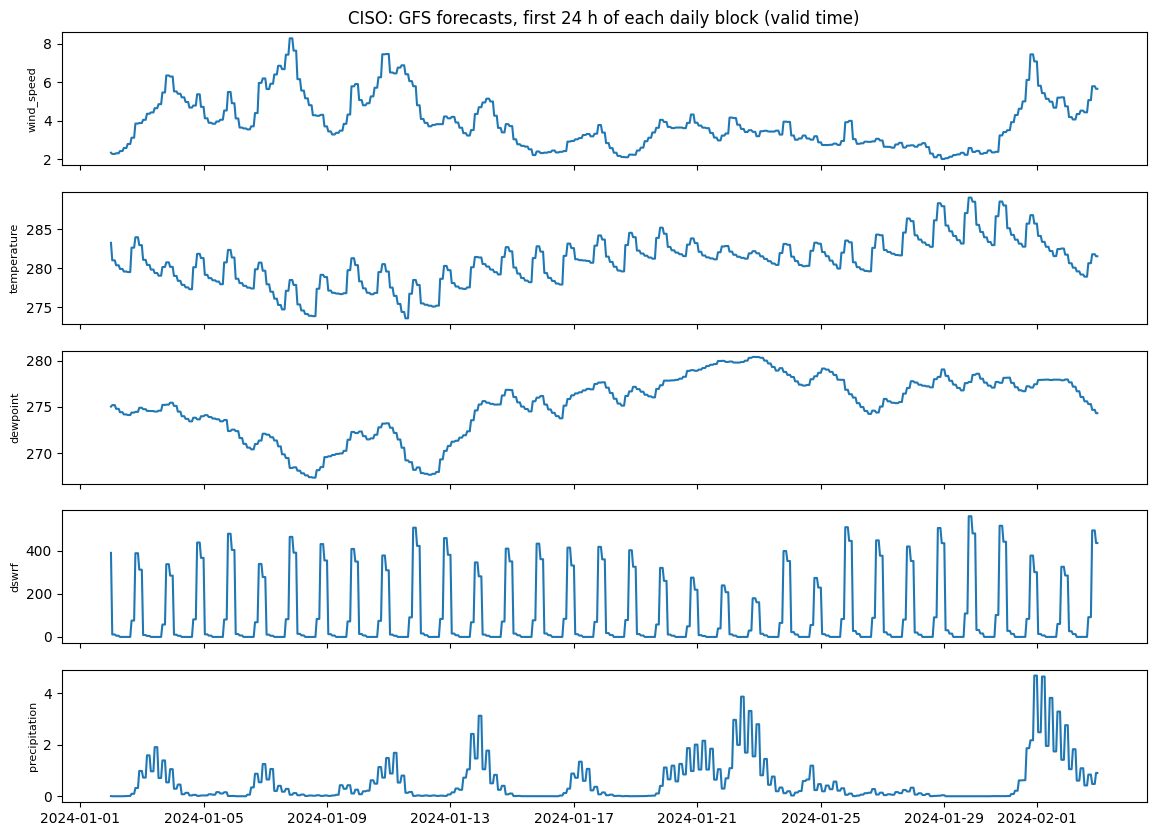

In [17]:
tables = load_cache(RUNS)
write_avg_csvs(tables, REGION, OUT / "weather_data")
agg = build_hourly_blocks(tables)
agg.to_csv(OUT / "weather_data" / f"{REGION}_aggregated_weather_data.csv")
wfc = shift_to_model_input(agg)
wfc.to_csv(OUT / f"{REGION}_weather_forecast.csv")
print(f"{len(wfc)//96} daily 96-h blocks written: {wfc.index[0].date()} -> {wfc.index[-96].date()}")
display(wfc.head())

fig, axes = plt.subplots(5, 1, figsize=(14, 10), sharex=True)
day1 = wfc.values.reshape(-1, 96, 5)[:, :24, :].reshape(-1, 5)        # first 24 h of each block = continuous series
t = pd.date_range(wfc.index[0] + pd.Timedelta(days=1), periods=len(day1), freq="h")   # valid time (block d -> d+1)
for i, c in enumerate(wfc.columns):
    axes[i].plot(t, day1[:, i]); axes[i].set_ylabel(c.replace("forecast_avg_", "").replace("_wMean", ""), fontsize=8)
axes[0].set_title(f"{REGION}: GFS forecasts, first 24 h of each daily block (valid time)"); plt.show()

### 5.4 Check against the bundled files (optional)

If your region is one of the repo's regions, this re-builds the repo's own `weather_forecast.csv` from the repo's `weather_data/<R>_AVG_*.csv` files with the functions above — a quick proof it reproduces the original processing exactly.

In [18]:
repo_wd = REPO / "data" / REGION / "weather_data"
if (repo_wd / f"{REGION}_AVG_TEMP.csv").exists():
    t_repo = read_avg_csvs(REGION, repo_wd)
    mine = shift_to_model_input(build_hourly_blocks(t_repo))
    ref = pd.read_csv(REPO / "data" / REGION / f"{REGION}_weather_forecast.csv").iloc[:, 1:].values[:len(mine)]
    print("max |difference| per column vs bundled file:", np.abs(mine.values - ref).max(axis=0))
else:
    print("No bundled weather files for", REGION)

max |difference| per column vs bundled file: [4.79616347e-14 5.11590770e-13 5.11590770e-13 4.88853402e-12
 5.32907052e-15]


## 6. What you have now

In [19]:
for p in sorted(OUT.rglob("*")):
    if p.is_file() and "gfs_cache" not in p.parts:
        print(f"{p.relative_to(OUT)!s:60s} {p.stat().st_size/1e6:8.2f} MB")

CISO.csv                                                         0.04 MB
CISO_direct_emissions.csv                                        0.05 MB
CISO_generation_raw.csv                                          0.04 MB
CISO_lifecycle_emissions.csv                                     0.05 MB
CISO_weather_forecast.csv                                        0.34 MB
fuel_forecast\CISO_clean.csv                                     0.04 MB
weather_data\CISO_aggregated_weather_data.csv                    0.35 MB
weather_data\CISO_AVG_DPT.csv                                    0.02 MB
weather_data\CISO_AVG_DSWRF.csv                                  0.02 MB
weather_data\CISO_AVG_PCP.csv                                    0.02 MB
weather_data\CISO_AVG_TEMP.csv                                   0.02 MB
weather_data\CISO_AVG_WIND_SPEED.csv                             0.02 MB


## 7. Using the data with CarbonCast

The files are in the repo's formats, so the remaining steps are the repo's own scripts (run from `src/`):

1. **Tier 1 – source production forecasts.** In `firstTierConfig.json`, point the region block at the new files and set the periods for your data:
   * `"IN_FILE_NAME_PREFIX": "../data_downloaded/<R>/fuel_forecast/<R>_"`, `"IN_FILE_NAME_SUFFIX": "_clean.csv"`
   * `"WEATHER_FORECAST_IN_FILE_NAME": "../data_downloaded/<R>/<R>_weather_forecast.csv"`
   * `"SOURCES"` = your sources in upper case, `"SOURCE_COL"` = their column positions, `PARTIAL_FORECAST_AVAILABILITY_LIST` = 1 where Section 3 added a day-ahead column
   * `TRAIN_TEST_PERIOD` → `DATASET_LIMITER` (hours of data to use) and `NUM_TEST_DAYS` for your date range.

   Then `python firstTierForecasts.py firstTierConfig.json`. It writes `fuel_forecast/<R>_ANN_DA_<source>_iter0.csv` (96-h forecasts per source).
2. **Tier-2 input file.** `*_96hr_forecasts.csv` is the 5 weather columns of `<R>_weather_forecast.csv` followed by one `avg_<source>_production_forecast` column per source from step 1, in 96-row daily blocks.
3. **Tier 2 – carbon intensity forecasts.** Add/adjust the region block in `secondTierConfig.json` (`*_CEF_IN_FILE_NAME` → `data_downloaded/<R>/<R>_<cef>_emissions.csv`, `FORECAST_IN_FILE_NAME`, `NUM_FORECAST_FEATURES`, `NUM_TEST_DAYS`, `NUM_VAL_DAYS`) and **train** with `python secondTierForecasts.py secondTierConfig.json -l` (no `-s`): the saved models only fit the 2020–2021 data they were trained on.

The prints below give a starting point for the two config blocks.

In [20]:
snippet1 = {REGION: {
    "IN_FILE_NAME_PREFIX": f"../data_downloaded/{REGION}/fuel_forecast/{REGION}_",
    "WEATHER_FORECAST_IN_FILE_NAME": f"../data_downloaded/{REGION}/{REGION}_weather_forecast.csv",
    "OUT_FILE_NAME_PREFIX": f"../data_downloaded/{REGION}/fuel_forecast/{REGION}_ANN_DA",
    "LOCAL_TIMEZONE": R["tz"], "NUM_FEATURES": 6, "NUM_WEATHER_FEATURES": 5, "START_COL": 1,
    "SOURCES": [s.upper() for s in SOURCES], "SOURCE_COL": list(range(len(SOURCES))),
    "PARTIAL_FORECAST_AVAILABILITY_LIST": [0 for _ in SOURCES], # this can be changed if we want to use day ahead forecasts from databases
    "PARTIAL_FORECAST_HOURS": 24}}
snippet2 = {REGION: {
    "LIFECYCLE_CEF_IN_FILE_NAME": f"../data_downloaded/{REGION}/{REGION}_lifecycle_emissions.csv",
    "DIRECT_CEF_IN_FILE_NAME": f"../data_downloaded/{REGION}/{REGION}_direct_emissions.csv",
    "FORECAST_IN_FILE_NAME": f"../data_downloaded/{REGION}/{REGION}_96hr_forecasts.csv",
    "LIFECYCLE_CEF_OUT_FILE_NAME_PREFIX": f"../CI_forecast_data/{REGION}/{REGION}_lifecycle_96hr_CI_forecasts",
    "DIRECT_CEF_OUT_FILE_NAME_PREFIX": f"../CI_forecast_data/{REGION}/{REGION}_direct_96hr_CI_forecasts",
    "LOCAL_TIMEZONE": R["tz"], "NUM_FEATURES": 6, "NUM_FORECAST_FEATURES": 5 + len(SOURCES), "START_COL": 1}}
print("firstTierConfig.json:\n", json.dumps(snippet1, indent=4))
print("\nsecondTierConfig.json:\n", json.dumps(snippet2, indent=4))
print("\nNote: START_COL is 1 because of the leading row-number column in the emissions file.")

firstTierConfig.json:
 {
    "CISO": {
        "IN_FILE_NAME_PREFIX": "../data_downloaded/CISO/fuel_forecast/CISO_",
        "WEATHER_FORECAST_IN_FILE_NAME": "../data_downloaded/CISO/CISO_weather_forecast.csv",
        "OUT_FILE_NAME_PREFIX": "../data_downloaded/CISO/fuel_forecast/CISO_ANN_DA",
        "LOCAL_TIMEZONE": "US/Pacific",
        "NUM_FEATURES": 6,
        "NUM_WEATHER_FEATURES": 5,
        "START_COL": 1,
        "SOURCES": [
            "COAL",
            "NAT_GAS",
            "NUCLEAR",
            "OIL",
            "HYDRO",
            "SOLAR",
            "WIND",
            "OTHER"
        ],
        "SOURCE_COL": [
            0,
            1,
            2,
            3,
            4,
            5,
            6,
            7
        ],
        "PARTIAL_FORECAST_AVAILABILITY_LIST": [
            0,
            0,
            0,
            0,
            0,
            0,
            0,
            0
        ],
        "PARTIAL_FORECAST_HOURS": 24
    }
}

s